RESULTADOS GLOBALES
Error máximo = 0.063773
Error RMS    = 0.015746

Intervalo: 0-100 ms
Error máximo = 0.061508
Error RMS    = 0.016922

Intervalo: 100-200 ms
Error máximo = 0.063773
Error RMS    = 0.016872

Intervalo: 200-300 ms
Error máximo = 0.060517
Error RMS    = 0.013145


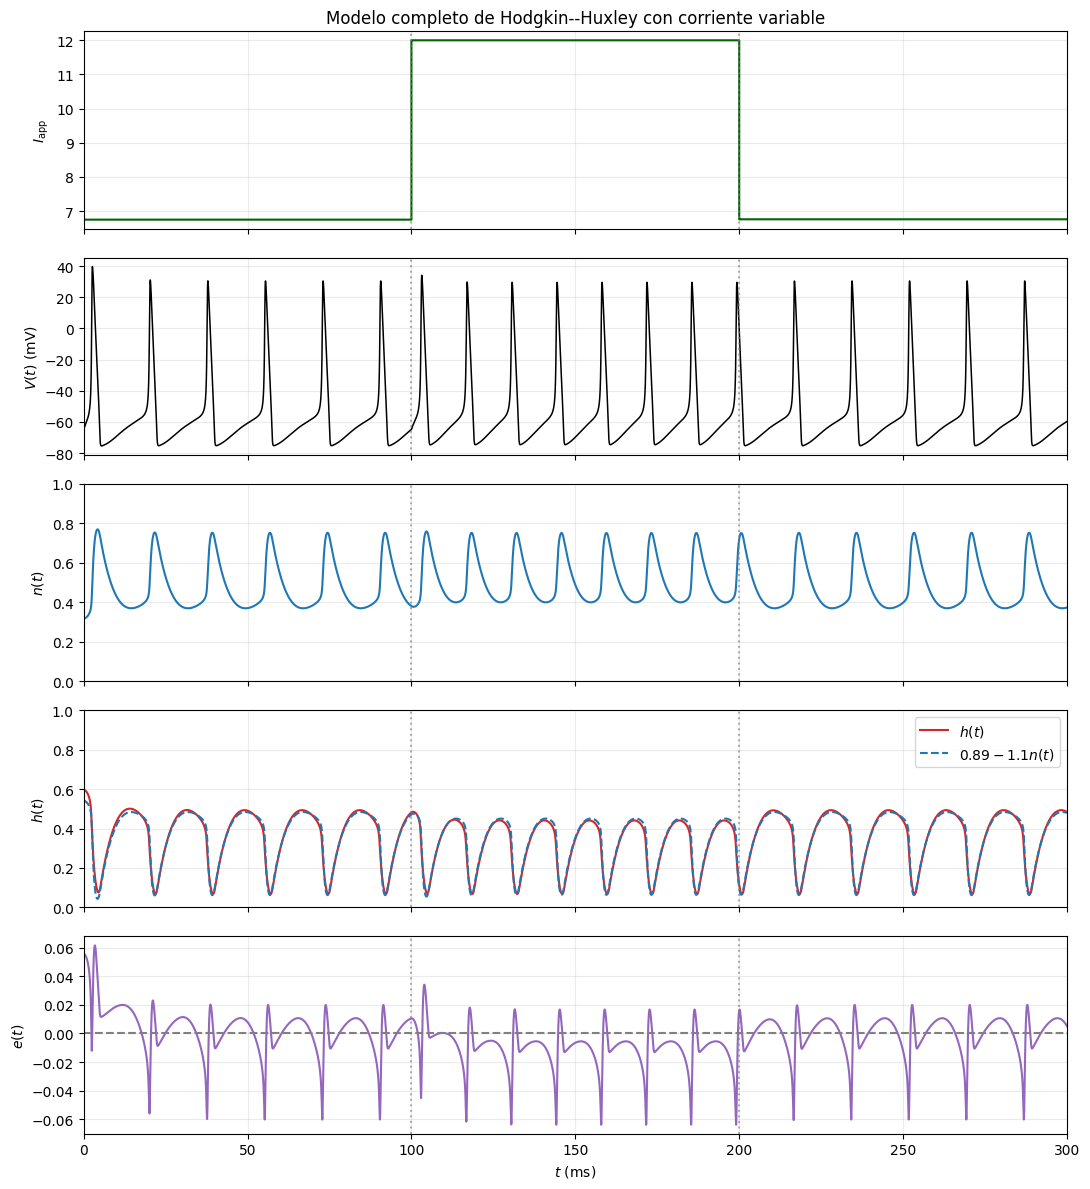

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================
# PARÁMETROS DEL MODELO HODGKIN-HUXLEY
# ============================================

C_m = 1.0
G_Na = 120.0
G_K = 36.0
G_L = 0.3

E_Na = 50.0
E_K = -77.0
E_L = -54.4

# ============================================
# CORRIENTE VARIABLE EN EL TIEMPO
# ============================================

def corriente_aplicada(t):
    if t < 100.0:
        return 6.75
    elif t < 200.0:
        return 12.0
    else:
        return 6.76

# ============================================
# FUNCIONES AUXILIARES
# ============================================

def vtrap(x, y):
    if abs(x / y) < 1e-6:
        return y * (1.0 - x / (2.0 * y))
    return x / np.expm1(x / y)


def alpha_m(V):
    return 0.1 * vtrap(-(V + 40.0), 10.0)


def beta_m(V):
    return 4.0 * np.exp(-(V + 65.0) / 18.0)


def alpha_h(V):
    return 0.07 * np.exp(-(V + 65.0) / 20.0)


def beta_h(V):
    return 1.0 / (
        1.0 + np.exp(-(V + 35.0) / 10.0)
    )


def alpha_n(V):
    return 0.01 * vtrap(-(V + 55.0), 10.0)


def beta_n(V):
    return 0.125 * np.exp(-(V + 65.0) / 80.0)


def estado_estacionario(alpha, beta, V):
    return alpha(V) / (alpha(V) + beta(V))

# ============================================
# MODELO COMPLETO DE HODGKIN-HUXLEY
# ============================================

def modelo_hh(t, y):

    V, m, h, n = y

    I_app = corriente_aplicada(t)

    I_Na = G_Na * m**3 * h * (V - E_Na)
    I_K = G_K * n**4 * (V - E_K)
    I_L = G_L * (V - E_L)

    dV = (
        I_app - I_Na - I_K - I_L
    ) / C_m

    dm = (
        alpha_m(V) * (1.0 - m)
        - beta_m(V) * m
    )

    dh = (
        alpha_h(V) * (1.0 - h)
        - beta_h(V) * h
    )

    dn = (
        alpha_n(V) * (1.0 - n)
        - beta_n(V) * n
    )

    return np.array([dV, dm, dh, dn])

# ============================================
# MÉTODO DE RUNGE-KUTTA DE ORDEN 4
# ============================================

def paso_rk4(f, t, y, dt):

    k1 = f(t, y)
    k2 = f(t + dt/2, y + dt*k1/2)
    k3 = f(t + dt/2, y + dt*k2/2)
    k4 = f(t + dt, y + dt*k3)

    return y + (dt/6) * (
        k1 + 2*k2 + 2*k3 + k4
    )

# ============================================
# CONDICIONES INICIALES
# ============================================

V_0 = -65.0

m_0 = estado_estacionario(
    alpha_m, beta_m, V_0
)

h_0 = estado_estacionario(
    alpha_h, beta_h, V_0
)

n_0 = estado_estacionario(
    alpha_n, beta_n, V_0
)

# ============================================
# SIMULACIÓN NUMÉRICA
# ============================================

dt = 0.01
t_final = 300.0

t = np.arange(
    0.0, t_final + dt/2, dt
)

solucion = np.zeros((len(t), 4))

solucion[0] = [
    V_0, m_0, h_0, n_0
]

for i in range(len(t) - 1):

    solucion[i+1] = paso_rk4(
        modelo_hh,
        t[i],
        solucion[i],
        dt
    )

V = solucion[:, 0]
m = solucion[:, 1]
h = solucion[:, 2]
n = solucion[:, 3]

I = np.array([
    corriente_aplicada(ti) for ti in t
])

# ============================================
# APROXIMACIÓN LINEAL Y ERROR
# ============================================

h_aprox = 0.89 - 1.1*n

error = h - h_aprox

error_max = np.max(np.abs(error))

error_rms = np.sqrt(
    np.mean(error**2)
)

print("RESULTADOS GLOBALES")
print(f"Error máximo = {error_max:.6f}")
print(f"Error RMS    = {error_rms:.6f}")

# ============================================
# ERRORES POR INTERVALO
# ============================================

intervalos = [
    (0, 100),
    (100, 200),
    (200, 300)
]

for a, b in intervalos:

    mascara = (t >= a) & (t < b)

    if b == 300:
        mascara = (t >= a) & (t <= b)

    e = error[mascara]

    Emax = np.max(np.abs(e))
    Erms = np.sqrt(np.mean(e**2))

    print(f"\nIntervalo: {a}-{b} ms")
    print(f"Error máximo = {Emax:.6f}")
    print(f"Error RMS    = {Erms:.6f}")

# ============================================
# GUARDAR RESULTADOS
# ============================================

np.savetxt(
    "HH_corriente_variable.csv",
    np.column_stack(
        (t, I, V, m, h, n, h_aprox, error)
    ),
    delimiter=",",
    header=(
        "t_ms,I_app,V_mV,m,h,n,"
        "h_aproximada,error"
    ),
    comments=""
)

# ============================================
# GRÁFICAS
# ============================================

fig, ax = plt.subplots(
    5, 1,
    figsize=(11, 12),
    sharex=True
)

ax[0].step(
    t, I,
    where="post",
    color="darkgreen"
)
ax[0].set_ylabel(r"$I_{\mathrm{app}}$")
ax[0].set_title(
    "Modelo completo de Hodgkin--Huxley "
    "con corriente variable"
)

ax[1].plot(
    t, V,
    color="black",
    linewidth=1.1
)
ax[1].set_ylabel(r"$V(t)$ (mV)")

ax[2].plot(
    t, n,
    color="tab:blue"
)
ax[2].set_ylabel(r"$n(t)$")
ax[2].set_ylim(0, 1)

ax[3].plot(
    t, h,
    color="tab:red",
    label=r"$h(t)$"
)
ax[3].plot(
    t, h_aprox,
    color="tab:blue",
    linestyle="--",
    label=r"$0.89-1.1n(t)$"
)
ax[3].set_ylabel(r"$h(t)$")
ax[3].set_ylim(0, 1)
ax[3].legend()

ax[4].plot(
    t, error,
    color="tab:purple"
)
ax[4].axhline(
    0,
    color="gray",
    linestyle="--"
)
ax[4].set_ylabel(r"$e(t)$")
ax[4].set_xlabel(r"$t$ (ms)")

for eje in ax:
    eje.grid(alpha=0.25)
    eje.set_xlim(0, 300)

    for cambio in [100, 200]:
        eje.axvline(
            cambio,
            color="gray",
            linestyle=":",
            alpha=0.6
        )

fig.tight_layout()

fig.savefig(
    "HH_corriente_variable.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()





ERROR CERCA DEL VALOR CRITICO DE HOPF
IH = 6.752633

       I_app         Emax         ERMS    Emax_post    ERMS_post
-----------------------------------------------------------------
    6.652633     0.061394     0.014544     0.060736     0.013777
    6.742633     0.061500     0.014458     0.060214     0.013745
    6.751633     0.061509     0.014438     0.060169     0.013723
    6.752533     0.061510     0.014436     0.060165     0.013721
    6.752733     0.061510     0.014435     0.060164     0.013720
    6.753633     0.061511     0.014433     0.060160     0.013718
    6.762633     0.061522     0.014414     0.060116     0.013697
    6.852633     0.061626     0.014257     0.059737     0.013535


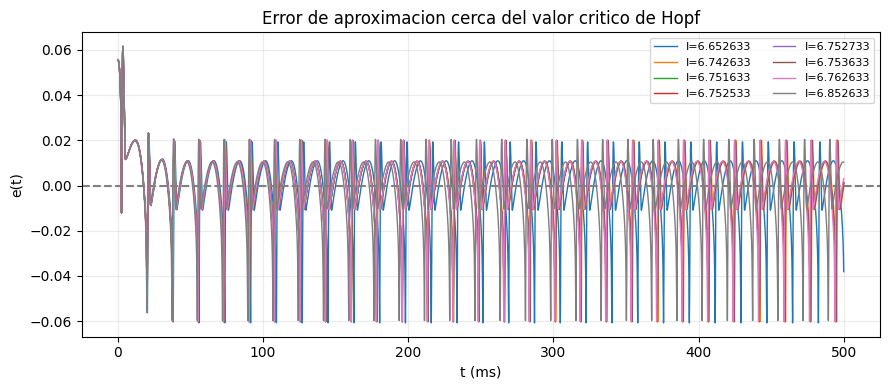

In [3]:

# ================================================
# ERROR DE APROXIMACION CERCA DEL PUNTO DE HOPF
# Modelo completo de Hodgkin-Huxley
# ================================================

import numpy as np
import matplotlib.pyplot as plt

IH = 6.752633

corrientes = [
    IH - 0.1,
    IH - 0.01,
    IH - 0.001,
    IH - 0.0001,
    IH + 0.0001,
    IH + 0.001,
    IH + 0.01,
    IH + 0.1
]

dt = 0.01
t_final = 500.0
t = np.arange(0, t_final + dt/2, dt)

# Conservamos las condiciones iniciales originales
y0 = np.array([V_0, m_0, h_0, n_0])

resultados = []
curvas_error = []

for I_constante in corrientes:

    # Modelo completo con corriente constante
    def modelo_constante(ti, y):
        V, m, h, n = y

        I_Na = G_Na * m**3 * h * (V - E_Na)
        I_K = G_K * n**4 * (V - E_K)
        I_L = G_L * (V - E_L)

        dV = (I_constante - I_Na - I_K - I_L) / C_m
        dm = alpha_m(V)*(1-m) - beta_m(V)*m
        dh = alpha_h(V)*(1-h) - beta_h(V)*h
        dn = alpha_n(V)*(1-n) - beta_n(V)*n

        return np.array([dV, dm, dh, dn])

    solucion = np.zeros((len(t), 4))
    solucion[0] = y0

    for i in range(len(t)-1):
        solucion[i+1] = paso_rk4(
            modelo_constante, t[i], solucion[i], dt
        )

    h = solucion[:, 2]
    n = solucion[:, 3]

    error = h - (0.89 - 1.1*n)

    Emax = np.max(np.abs(error))
    Erms = np.sqrt(np.mean(error**2))

    # Error despues de descartar 150 ms
    mascara = t >= 150.0
    error_post = error[mascara]

    Emax_post = np.max(np.abs(error_post))
    Erms_post = np.sqrt(np.mean(error_post**2))

    resultados.append([
        I_constante, Emax, Erms,
        Emax_post, Erms_post
    ])

    curvas_error.append(error)

# ================================================
# TABLA DE RESULTADOS
# ================================================

print("ERROR CERCA DEL VALOR CRITICO DE HOPF")
print(f"IH = {IH:.6f}")
print()
print(
    f"{'I_app':>12} {'Emax':>12} {'ERMS':>12} "
    f"{'Emax_post':>12} {'ERMS_post':>12}"
)
print("-"*65)

for fila in resultados:
    print(
        f"{fila[0]:12.6f} {fila[1]:12.6f} "
        f"{fila[2]:12.6f} {fila[3]:12.6f} "
        f"{fila[4]:12.6f}"
    )

# ================================================
# GUARDAR TABLA
# ================================================

np.savetxt(
    "HH_error_cerca_Hopf.csv",
    np.array(resultados),
    delimiter=",",
    header="I_app,Emax,ERMS,Emax_post150,ERMS_post150",
    comments=""
)

# ================================================
# GRAFICO DEL ERROR
# ================================================

plt.figure(figsize=(9, 4))

for I_constante, error in zip(corrientes, curvas_error):
    plt.plot(
        t, error,
        linewidth=1,
        label=f"I={I_constante:.6f}"
    )

plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("t (ms)")
plt.ylabel("e(t)")
plt.title("Error de aproximacion cerca del valor critico de Hopf")
plt.grid(alpha=0.25)
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()

plt.savefig(
    "HH_error_cerca_Hopf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [4]:

# COMPROBACION DE ESTABILIDAD NUMERICA CERCA DE HOPF

from scipy.integrate import solve_ivp
import numpy as np

IH = 6.752633
corrientes_prueba = [IH - 0.0001, IH, IH + 0.0001]
pasos = [0.01, 0.005]

print("COMPROBACION NUMERICA CERCA DE HOPF")
print(f"{'I_app':>12} {'dt':>9} {'Emax':>12} {'ERMS':>12}")
print("-" * 50)

for I_constante in corrientes_prueba:

    def modelo_constante(t, y):
        V, m, h, n = y

        I_Na = G_Na*m**3*h*(V-E_Na)
        I_K = G_K*n**4*(V-E_K)
        I_L = G_L*(V-E_L)

        return [
            (I_constante-I_Na-I_K-I_L)/C_m,
            alpha_m(V)*(1-m)-beta_m(V)*m,
            alpha_h(V)*(1-h)-beta_h(V)*h,
            alpha_n(V)*(1-n)-beta_n(V)*n
        ]

    for dt_prueba in pasos:
        tiempos = np.linspace(
            0, 500, round(500/dt_prueba)+1
        )

        sol = solve_ivp(
            modelo_constante,
            (0, 500),
            [V_0, m_0, h_0, n_0],
            method="RK45",
            t_eval=tiempos,
            rtol=1e-10,
            atol=1e-12,
            max_step=dt_prueba
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        h = sol.y[2]
        n = sol.y[3]
        error = h-(0.89-1.1*n)

        Emax = np.max(np.abs(error))
        Erms = np.sqrt(np.mean(error**2))

        print(
            f"{I_constante:12.6f} "
            f"{dt_prueba:9.3f} "
            f"{Emax:12.6f} "
            f"{Erms:12.6f}"
        )


COMPROBACION NUMERICA CERCA DE HOPF
       I_app        dt         Emax         ERMS
--------------------------------------------------
    6.752533     0.010     0.061510     0.014436
    6.752533     0.005     0.061511     0.014435
    6.752633     0.010     0.061510     0.014436
    6.752633     0.005     0.061511     0.014435
    6.752733     0.010     0.061510     0.014435
    6.752733     0.005     0.061512     0.014435
